# River-1 quickstart

Simulate the weekly MMM dataset of PyMC-Marketing's
[MMM example](https://www.pymc-marketing.io/en/stable/notebooks/mmm/mmm_example.html) with its
adstock and saturation transformers, load River-1 from the Hub and decompose the sales: the model
sees the outcome of the first 80% of the weeks (context) and decomposes both the context and the
remaining 20% (query), with no model fit.

Requires `pip install 'pymc-mfm[hub,diagnostics,examples]'` and access to the private
`pymc-labs/mfm` repository (`hf auth login`).

In [1]:
from pathlib import Path
from tempfile import TemporaryDirectory

import matplotlib.pyplot as plt
import numpy as np
import torch
import xarray as xr
from pymc_marketing.mmm.transformers import geometric_adstock, logistic_saturation

from pymc_mfm import decompose, from_pretrained
from pymc_mfm.plotting.panels import COLORS

# 200 dpi, the resolution of PyMC-Marketing's notebooks (100 dpi, retina): sharper, larger figures.
plt.rcParams["figure.dpi"] = 200

## 1. Load River-1

The bundle (about 10 MB) is downloaded into a temporary folder at a pinned repository commit.

In [2]:
workspace = TemporaryDirectory(prefix="river-1-")
model = from_pretrained(
    "pymc-labs/mfm",
    profile="river-1",
    revision="970e6095f14824d7e25ecace7e20a47bebde35b8",
    cache_dir=Path(workspace.name) / "hub",
)
print(f"{sum(p.numel() for p in model.parameters()):,} parameters")
model.config

2,443,583 parameters


ModelConfig(d_model=128, n_layers=4, n_heads=8, d_ff=512, flow_hidden=256, n_controls=10, n_demand=1)

## 2. Generate the data

The PyMC-Marketing data-generating process: two channels with geometric adstock (8-week maximum
lag) and logistic saturation, both from `pymc_marketing.mmm.transformers`, a trend, yearly
seasonality, two one-week events, an intercept and Gaussian noise, in sales units (thousands). The
series has 208 weeks, the history length River-1 was trained on.

In [3]:
seed = sum(map(ord, "mmm"))
rng = np.random.default_rng(seed=seed)
N_WEEKS = 208
dates = np.datetime64("2018-04-02") + 7 * np.arange(N_WEEKS)
dayofyear = (dates - dates.astype("datetime64[Y]")).astype(int) + 1

x1 = rng.uniform(low=0.0, high=1.0, size=N_WEEKS)
x1 = np.where(x1 > 0.9, x1, x1 / 2)
x2 = rng.uniform(low=0.0, high=1.0, size=N_WEEKS)
x2 = np.where(x2 > 0.8, x2, 0.0)

In [4]:
SCALE = 1_000
x1_adstock = geometric_adstock(
    xr.DataArray(x1, dims="week"), alpha=0.4, l_max=8, normalize=True, dim="week"
)
x2_adstock = geometric_adstock(
    xr.DataArray(x2, dims="week"), alpha=0.2, l_max=8, normalize=True, dim="week"
)
media = np.column_stack(
    [
        3.0 * logistic_saturation(x1_adstock, lam=4.0).eval(),
        2.0 * logistic_saturation(x2_adstock, lam=3.0).eval(),
    ]
)
trend = (np.linspace(start=0.0, stop=50, num=N_WEEKS) + 10) ** (1 / 4) - 1
seasonality = 0.5 * (
    -np.sin(2 * 2 * np.pi * dayofyear / 365.5) + np.cos(1 * 2 * np.pi * dayofyear / 365.5)
)
events = np.column_stack(
    [dates == np.datetime64("2019-05-13"), dates == np.datetime64("2020-09-14")]
).astype(float)
epsilon = rng.normal(loc=0.0, scale=0.25, size=N_WEEKS)

# True contributions in sales units.
baseline = SCALE * (2.0 + trend + seasonality)
channel_truth = SCALE * media
event_truth = SCALE * events * [1.5, 2.5]
y = baseline + channel_truth.sum(axis=1) + event_truth.sum(axis=1) + SCALE * epsilon

## 3. Split context and query

The model receives spend and controls for every week, but sales only for the context weeks.

166 context weeks, 42 query weeks


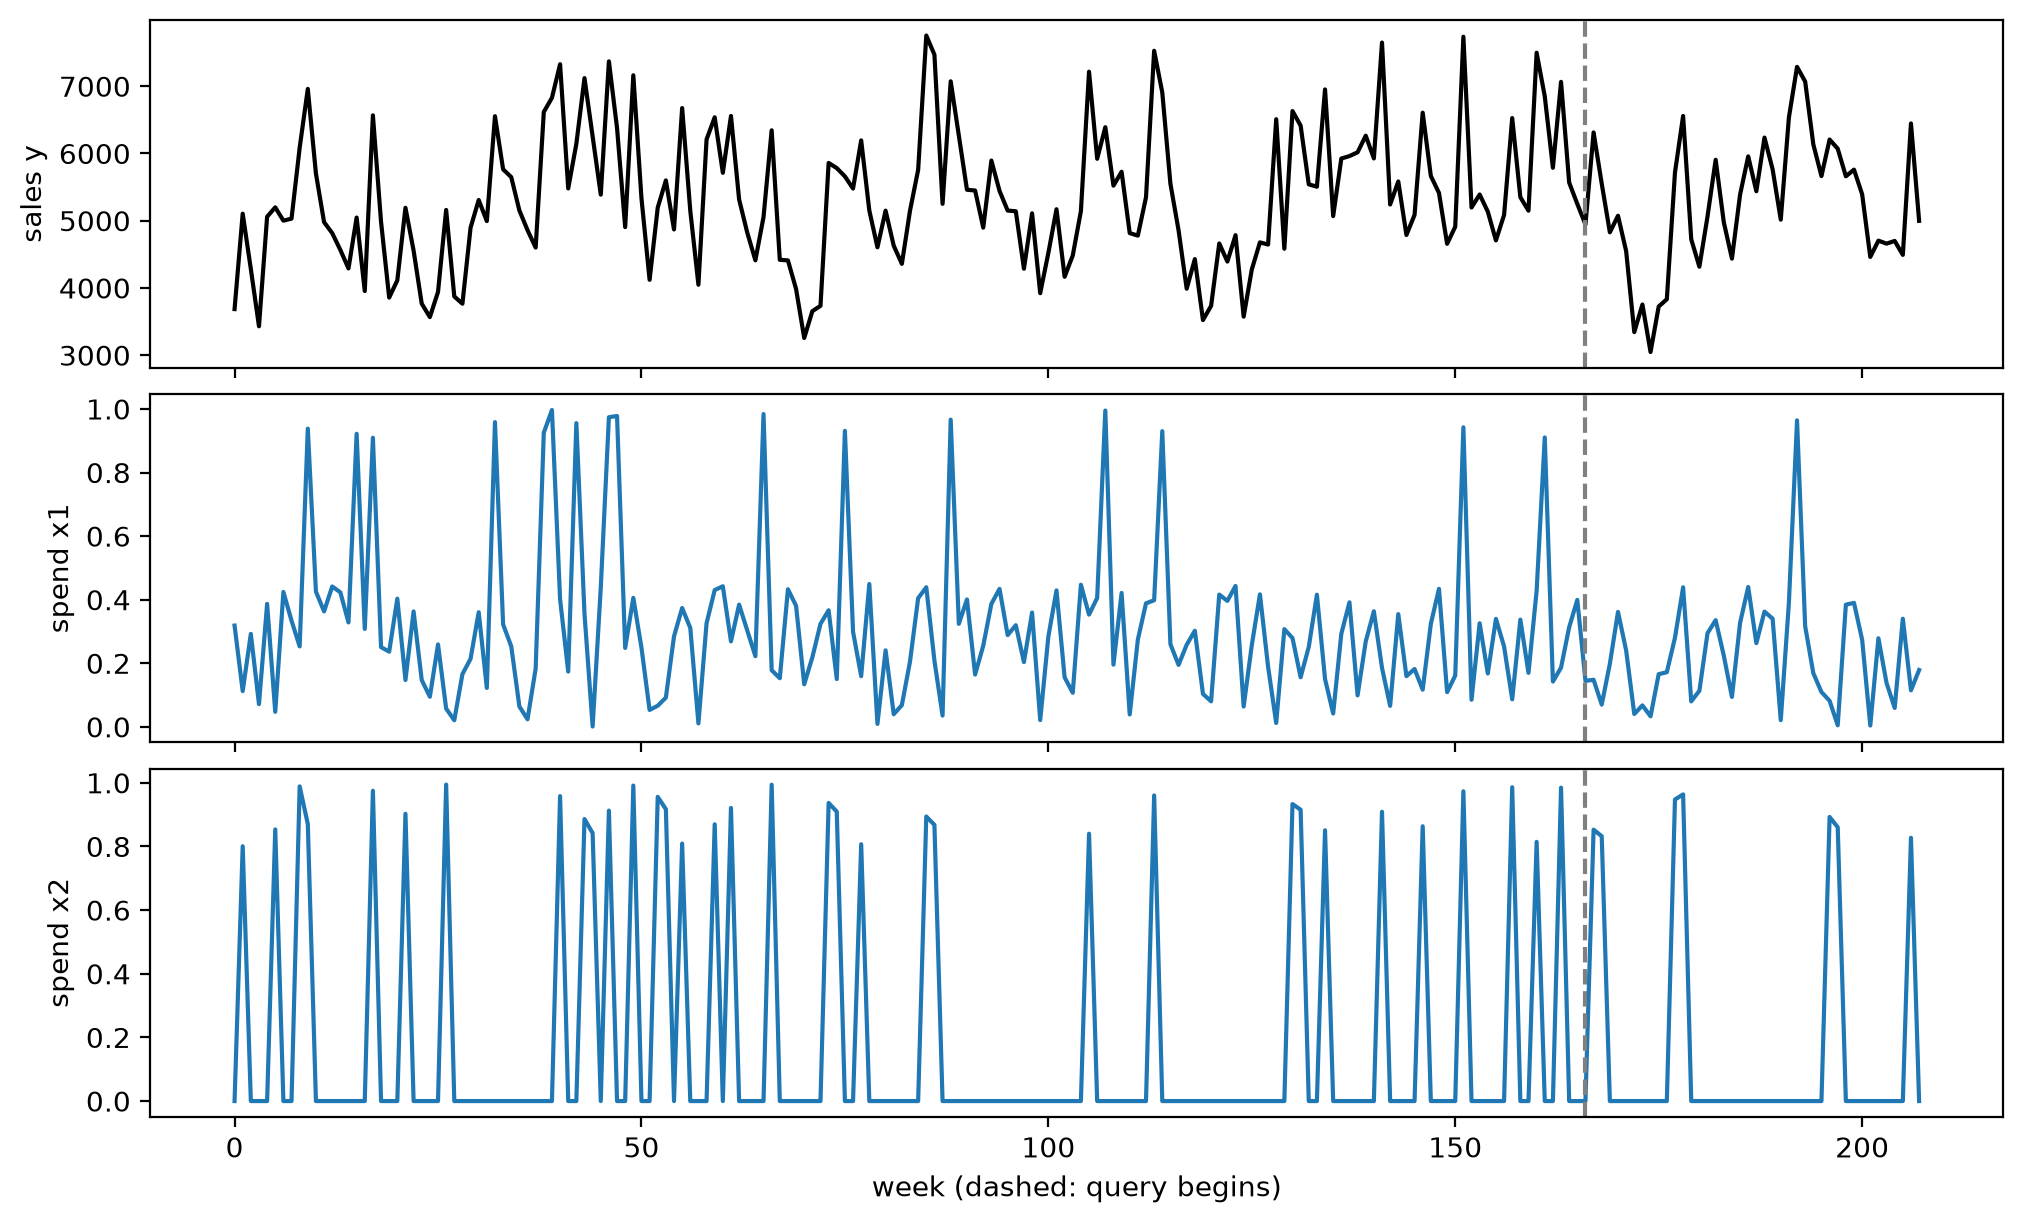

In [5]:
CONTEXT = int(0.8 * N_WEEKS)
print(f"{CONTEXT} context weeks, {N_WEEKS - CONTEXT} query weeks")

fig, axes = plt.subplots(3, 1, figsize=(10, 6), sharex=True, layout="constrained")
for ax, values, label in zip(axes, (y, x1, x2), ("sales y", "spend x1", "spend x2"), strict=True):
    ax.plot(values, color="black" if label == "sales y" else None)
    ax.axvline(CONTEXT, color="0.5", linestyle="--")
    ax.set_ylabel(label)
axes[-1].set_xlabel("week (dashed: query begins)");

## 4. Decompose

River-1 has 10 control slots: the two events fill the first two and the mask marks the rest as
unused. Intercept, trend and seasonality belong to the model's baseline. Context and query are
decomposed separately, each with 1,000 posterior draws instead of the default 32.

In [6]:
controls = np.zeros((N_WEEKS, model.config.n_controls))
controls[:, :2] = events
observations = {
    "spend": np.column_stack([x1, x2]),
    "controls": controls,
    "context_outcome": y[:CONTEXT],
    "control_mask": [1, 1] + [0] * (model.config.n_controls - 2),
}
names = {
    "channel_names": ("x1", "x2"),
    "control_names": ("event_1", "event_2", *(f"unused_{i}" for i in range(2, 10))),
}
torch.manual_seed(0)
context = decompose(model, observations, n_samples=1_000, window="context", **names)
query = decompose(model, observations, n_samples=1_000, window="query", **names)
query.components.shape  # [draw, week, component]

(1000, 42, 17)

## 5. Contributions

Window totals against the truth, with the x1 share of media contribution (0.81 over the
PyMC-Marketing example's 179 weeks):

In [7]:
def compare(result, weeks):
    truth = {
        "baseline": baseline[weeks],
        "channel:x1": channel_truth[weeks, 0],
        "channel:x2": channel_truth[weeks, 1],
    }
    print(f"{result.window} window ({result.components.shape[1]} weeks)")
    means = {}
    for name, values in truth.items():
        draws = result.components[:, :, result.component_names.index(name)].sum(axis=1)
        low, high = np.quantile(draws, [0.05, 0.95])
        means[name] = draws.mean()
        print(
            f"  {name:<11} truth {values.sum():>9,.0f}  "
            f"posterior mean {means[name]:>9,.0f}  90% [{low:,.0f}, {high:,.0f}]"
        )
    true_share = truth["channel:x1"].sum() / (truth["channel:x1"] + truth["channel:x2"]).sum()
    share = means["channel:x1"] / (means["channel:x1"] + means["channel:x2"])
    print(f"  x1 share    truth {true_share:.2f}  posterior mean {share:.2f}")


compare(context, slice(None, CONTEXT))
compare(query, slice(CONTEXT, None))

context window (166 weeks)
  baseline    truth   549,086  posterior mean   491,523  90% [373,507, 605,464]
  channel:x1  truth   261,603  posterior mean   205,599  90% [124,996, 280,093]
  channel:x2  truth    70,252  posterior mean    62,515  90% [52,521, 73,018]
  x1 share    truth 0.79  posterior mean 0.77
query window (42 weeks)
  baseline    truth   155,333  posterior mean   150,104  90% [97,210, 202,096]
  channel:x1  truth    51,407  posterior mean    33,646  90% [21,417, 47,060]
  channel:x2  truth    13,690  posterior mean    12,833  90% [10,375, 15,513]
  x1 share    truth 0.79  posterior mean 0.72


## 6. Sales in the query weeks

The sum of the components is the model's sales in weeks whose outcome it never saw; it excludes
observation noise.

mean absolute error 760
held-out weeks inside the 90% interval: 90%


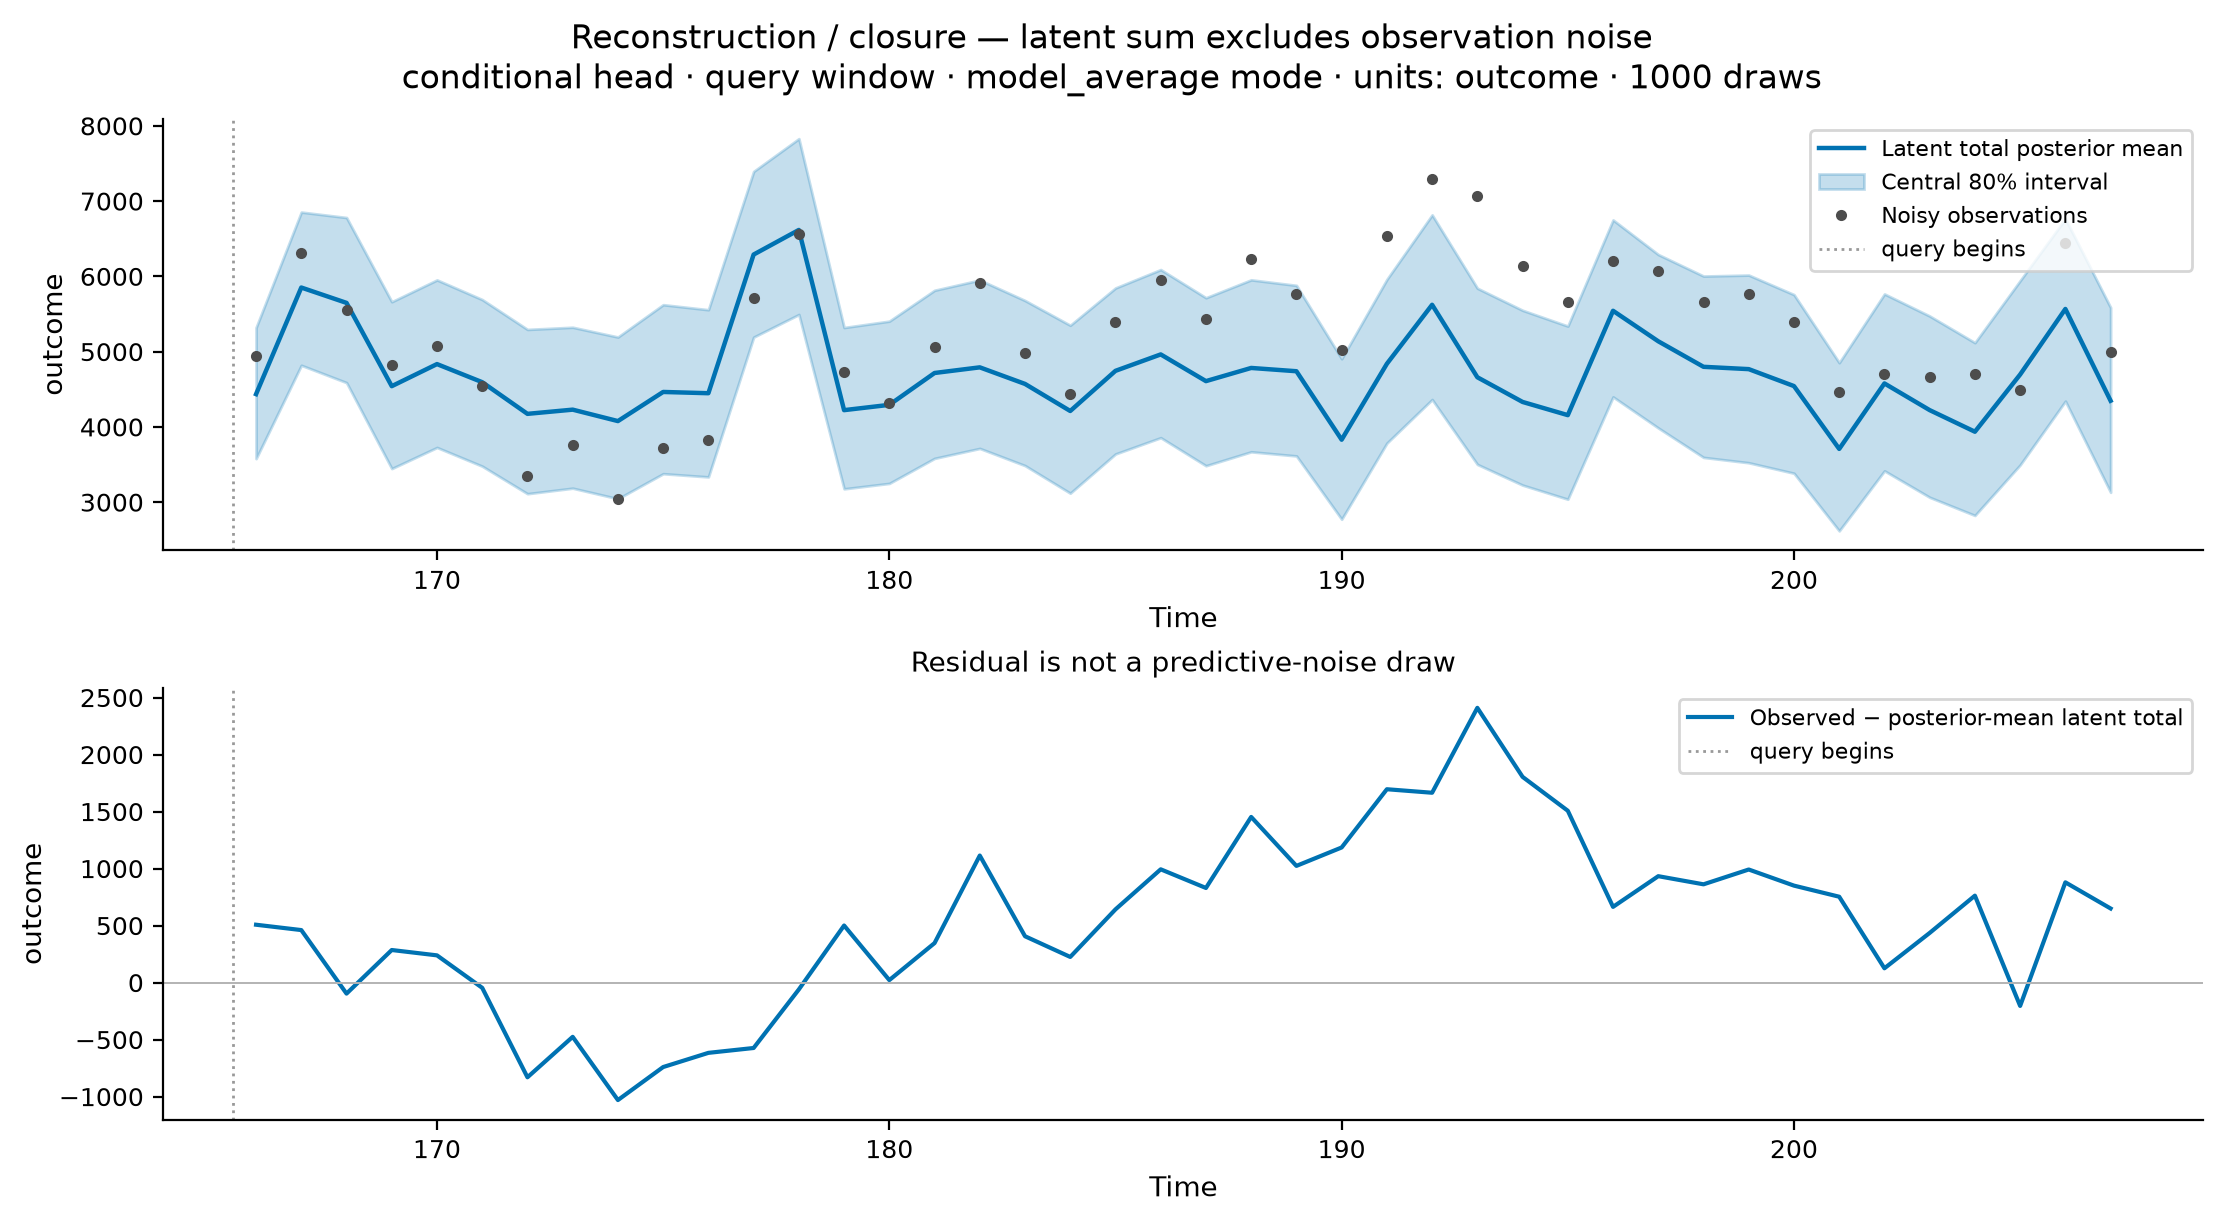

In [8]:
sales = query.components.sum(axis=2)
low, high = np.quantile(sales, [0.05, 0.95], axis=0)
held_out = y[CONTEXT:]
print(f"mean absolute error {np.abs(sales.mean(axis=0) - held_out).mean():,.0f}")
print(
    f"held-out weeks inside the 90% interval: {np.mean((low <= held_out) & (held_out <= high)):.0%}"
)
query.plot.reconstruction(observed=held_out)

## 7. Recovery

Each channel's and control's contribution week by week: the posterior mean with its central 80%
interval against the true contribution (dashed). Then the posterior distribution of each effect
against its true value (dashed): a channel's total over the window and an event's contribution in
its week. Both events fall in the context weeks, so the query shows the channels only; the mask
leaves the unused control slots out.

In [9]:
# True contributions in the result's component order (baseline, channels, controls, latent,
# indirect); the unused control slots, latent and indirect components are zero.
truth = np.column_stack(
    [baseline, channel_truth, event_truth, np.zeros((N_WEEKS, len(query.component_names) - 5))]
)
context_diagnostics = context.diagnostics(truth=truth[:CONTEXT])
query_diagnostics = query.diagnostics(truth=truth[CONTEXT:])


def plot_effect_posteriors(result, effects):
    """Posterior draws of each effect, summed over its weeks, against its true value."""
    rows = len(effects) // 2
    fig, axes = plt.subplots(rows, 2, figsize=(12, 3.5 * rows), squeeze=False, layout="constrained")
    for ax, (name, weeks) in zip(axes.flat, effects.items(), strict=True):
        index = result.component_names.index(name)
        ax.hist(
            result.components[:, np.isin(result.time, weeks), index].sum(axis=1),
            bins=40,
            color=COLORS[name.split(":")[0]],
            alpha=0.6,
            label="Posterior draws",
        )
        ax.axvline(truth[weeks, index].sum(), color="black", linestyle="--", label="Truth")
        ax.spines[["top", "right"]].set_visible(False)
        span = f"in week {weeks[0]}" if len(weeks) == 1 else f"over weeks {weeks[0]}–{weeks[-1]}"
        ax.set(title=name, xlabel=f"Contribution {span} (sales)", ylabel="Draws")
    axes[0, 0].legend()
    fig.suptitle(f"Effect posteriors — {result.window} window, {len(result.components)} draws")

### Context

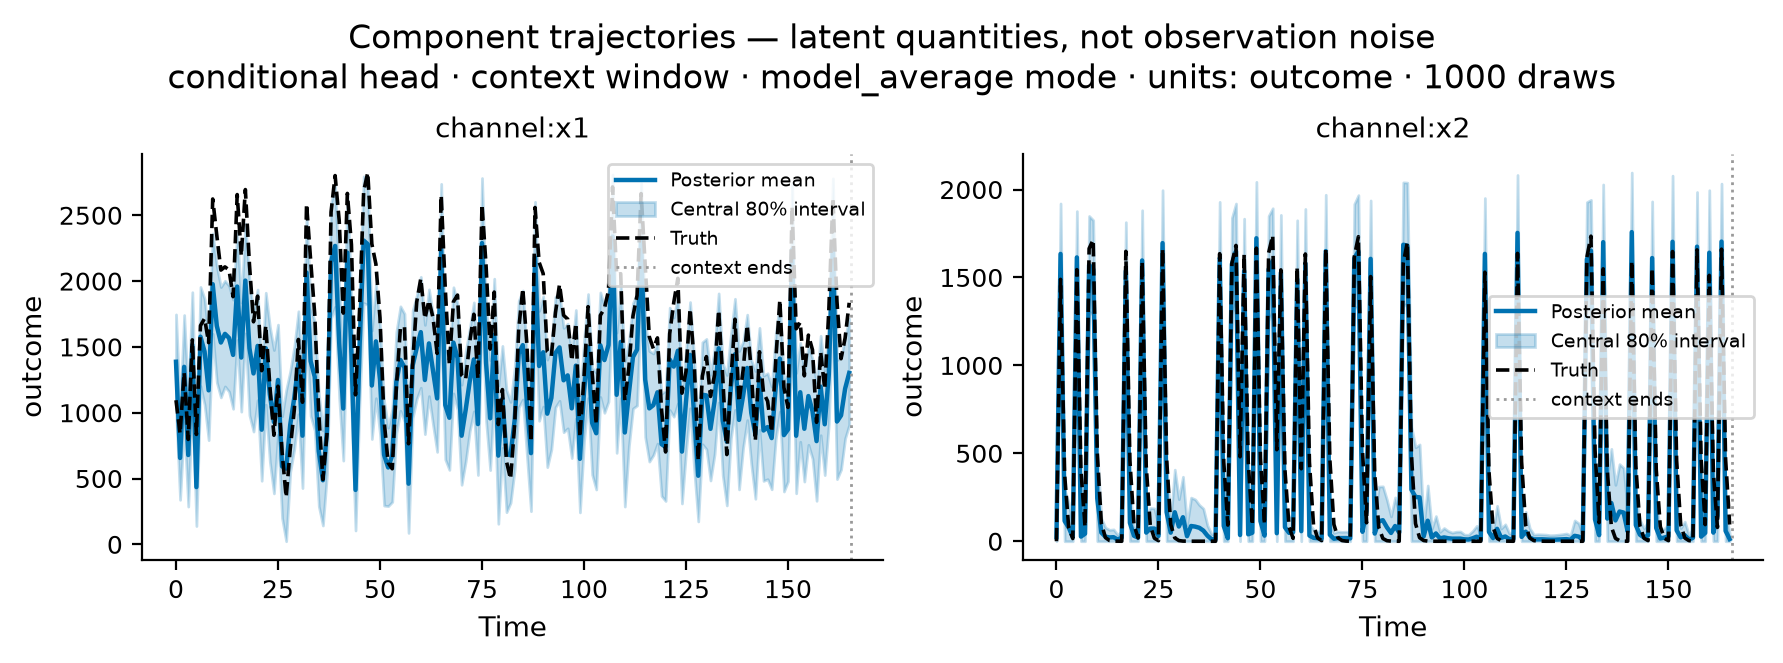

In [10]:
context_diagnostics.plot.channels()

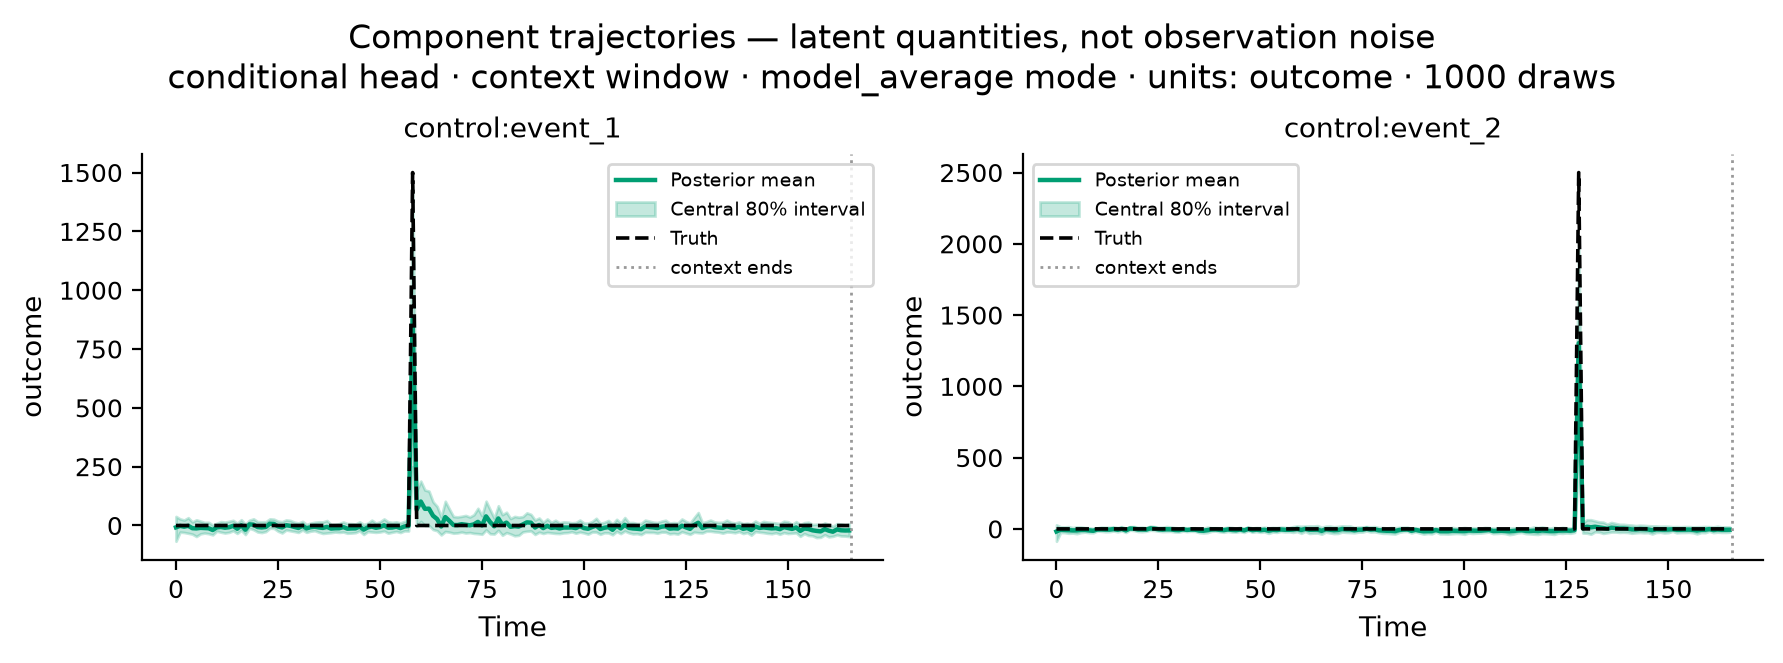

In [11]:
context_diagnostics.plot.controls()

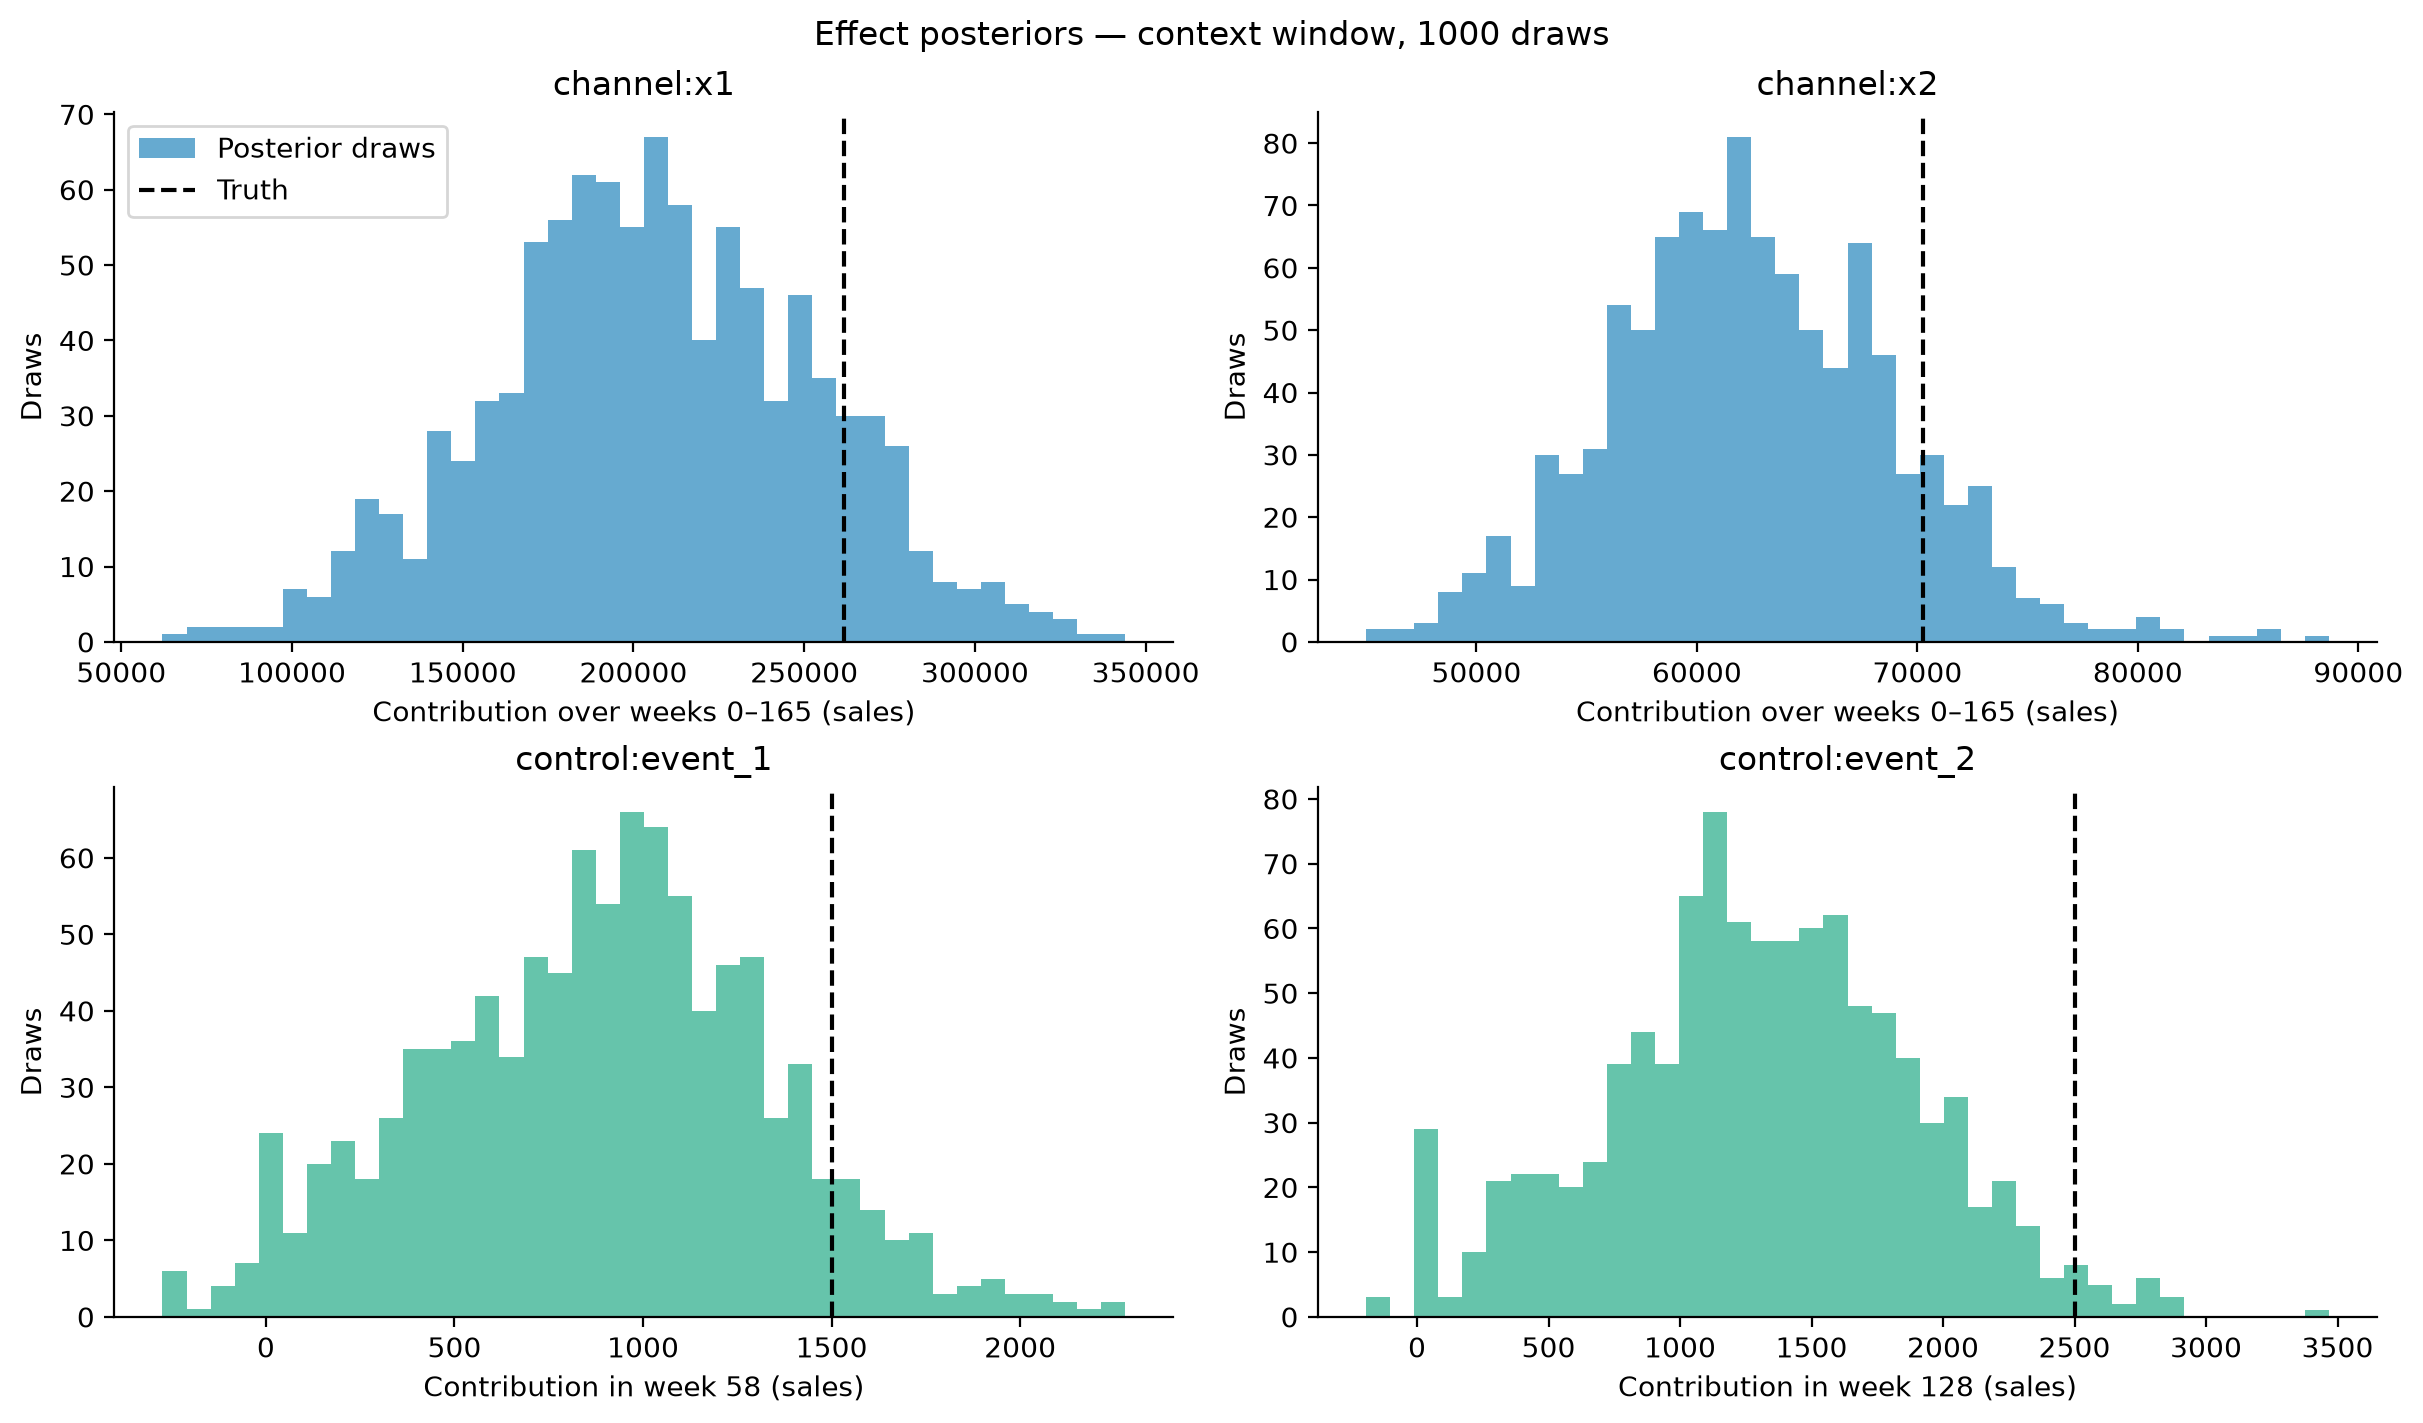

In [12]:
plot_effect_posteriors(
    context,
    {
        "channel:x1": context.time,
        "channel:x2": context.time,
        "control:event_1": np.flatnonzero(events[:, 0]),
        "control:event_2": np.flatnonzero(events[:, 1]),
    },
)

### Query

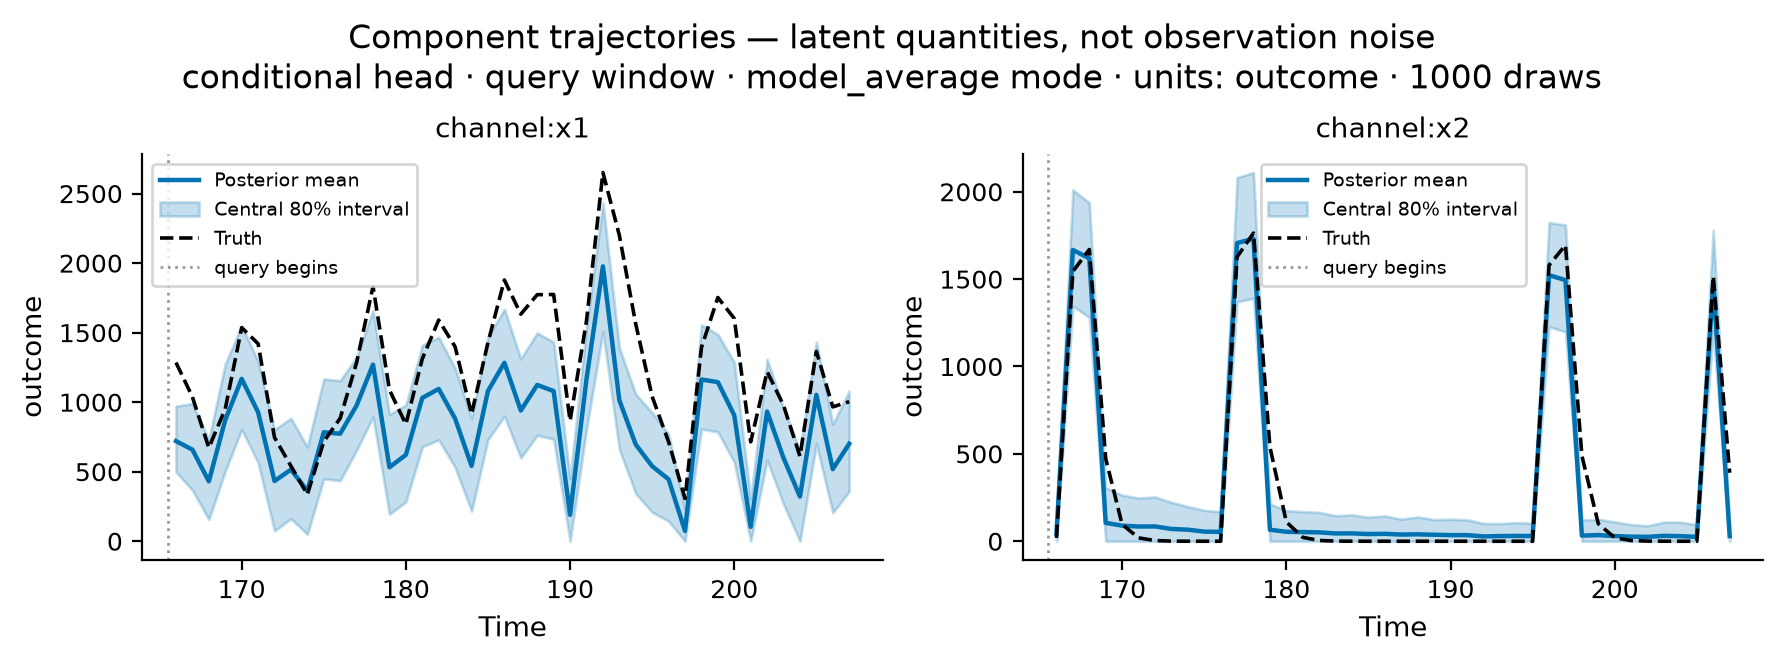

In [13]:
query_diagnostics.plot.channels()

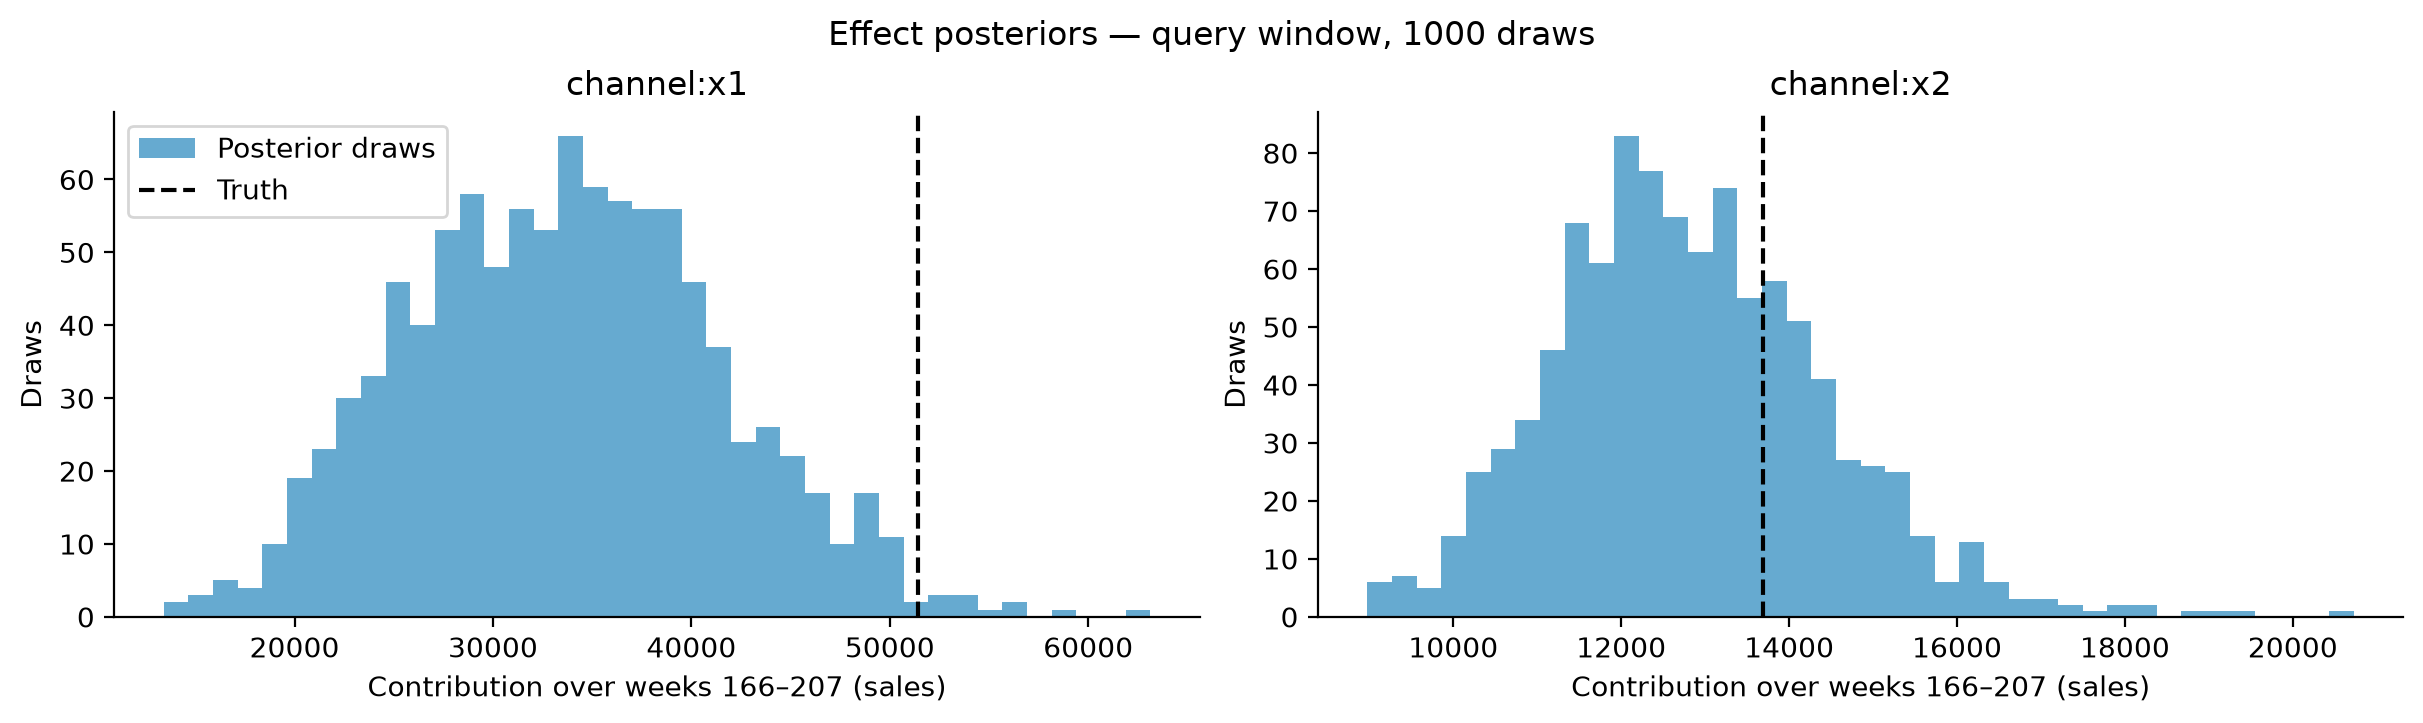

In [14]:
plot_effect_posteriors(query, {"channel:x1": query.time, "channel:x2": query.time})

## 8. Spend and network contributions

Each point is one week's **network posterior mean contribution**, in sales units, for x1 or x2.
Context and held-out query weeks are shown separately.

The top row uses **raw spend X**; the bottom row uses **adstocked X**, computed over the full
history before splitting the windows. Because the generator applies adstock before saturation,
a week's contribution also depends on previous spend. These are scatter plots of weekly
decompositions, not counterfactual response curves estimated by the network.

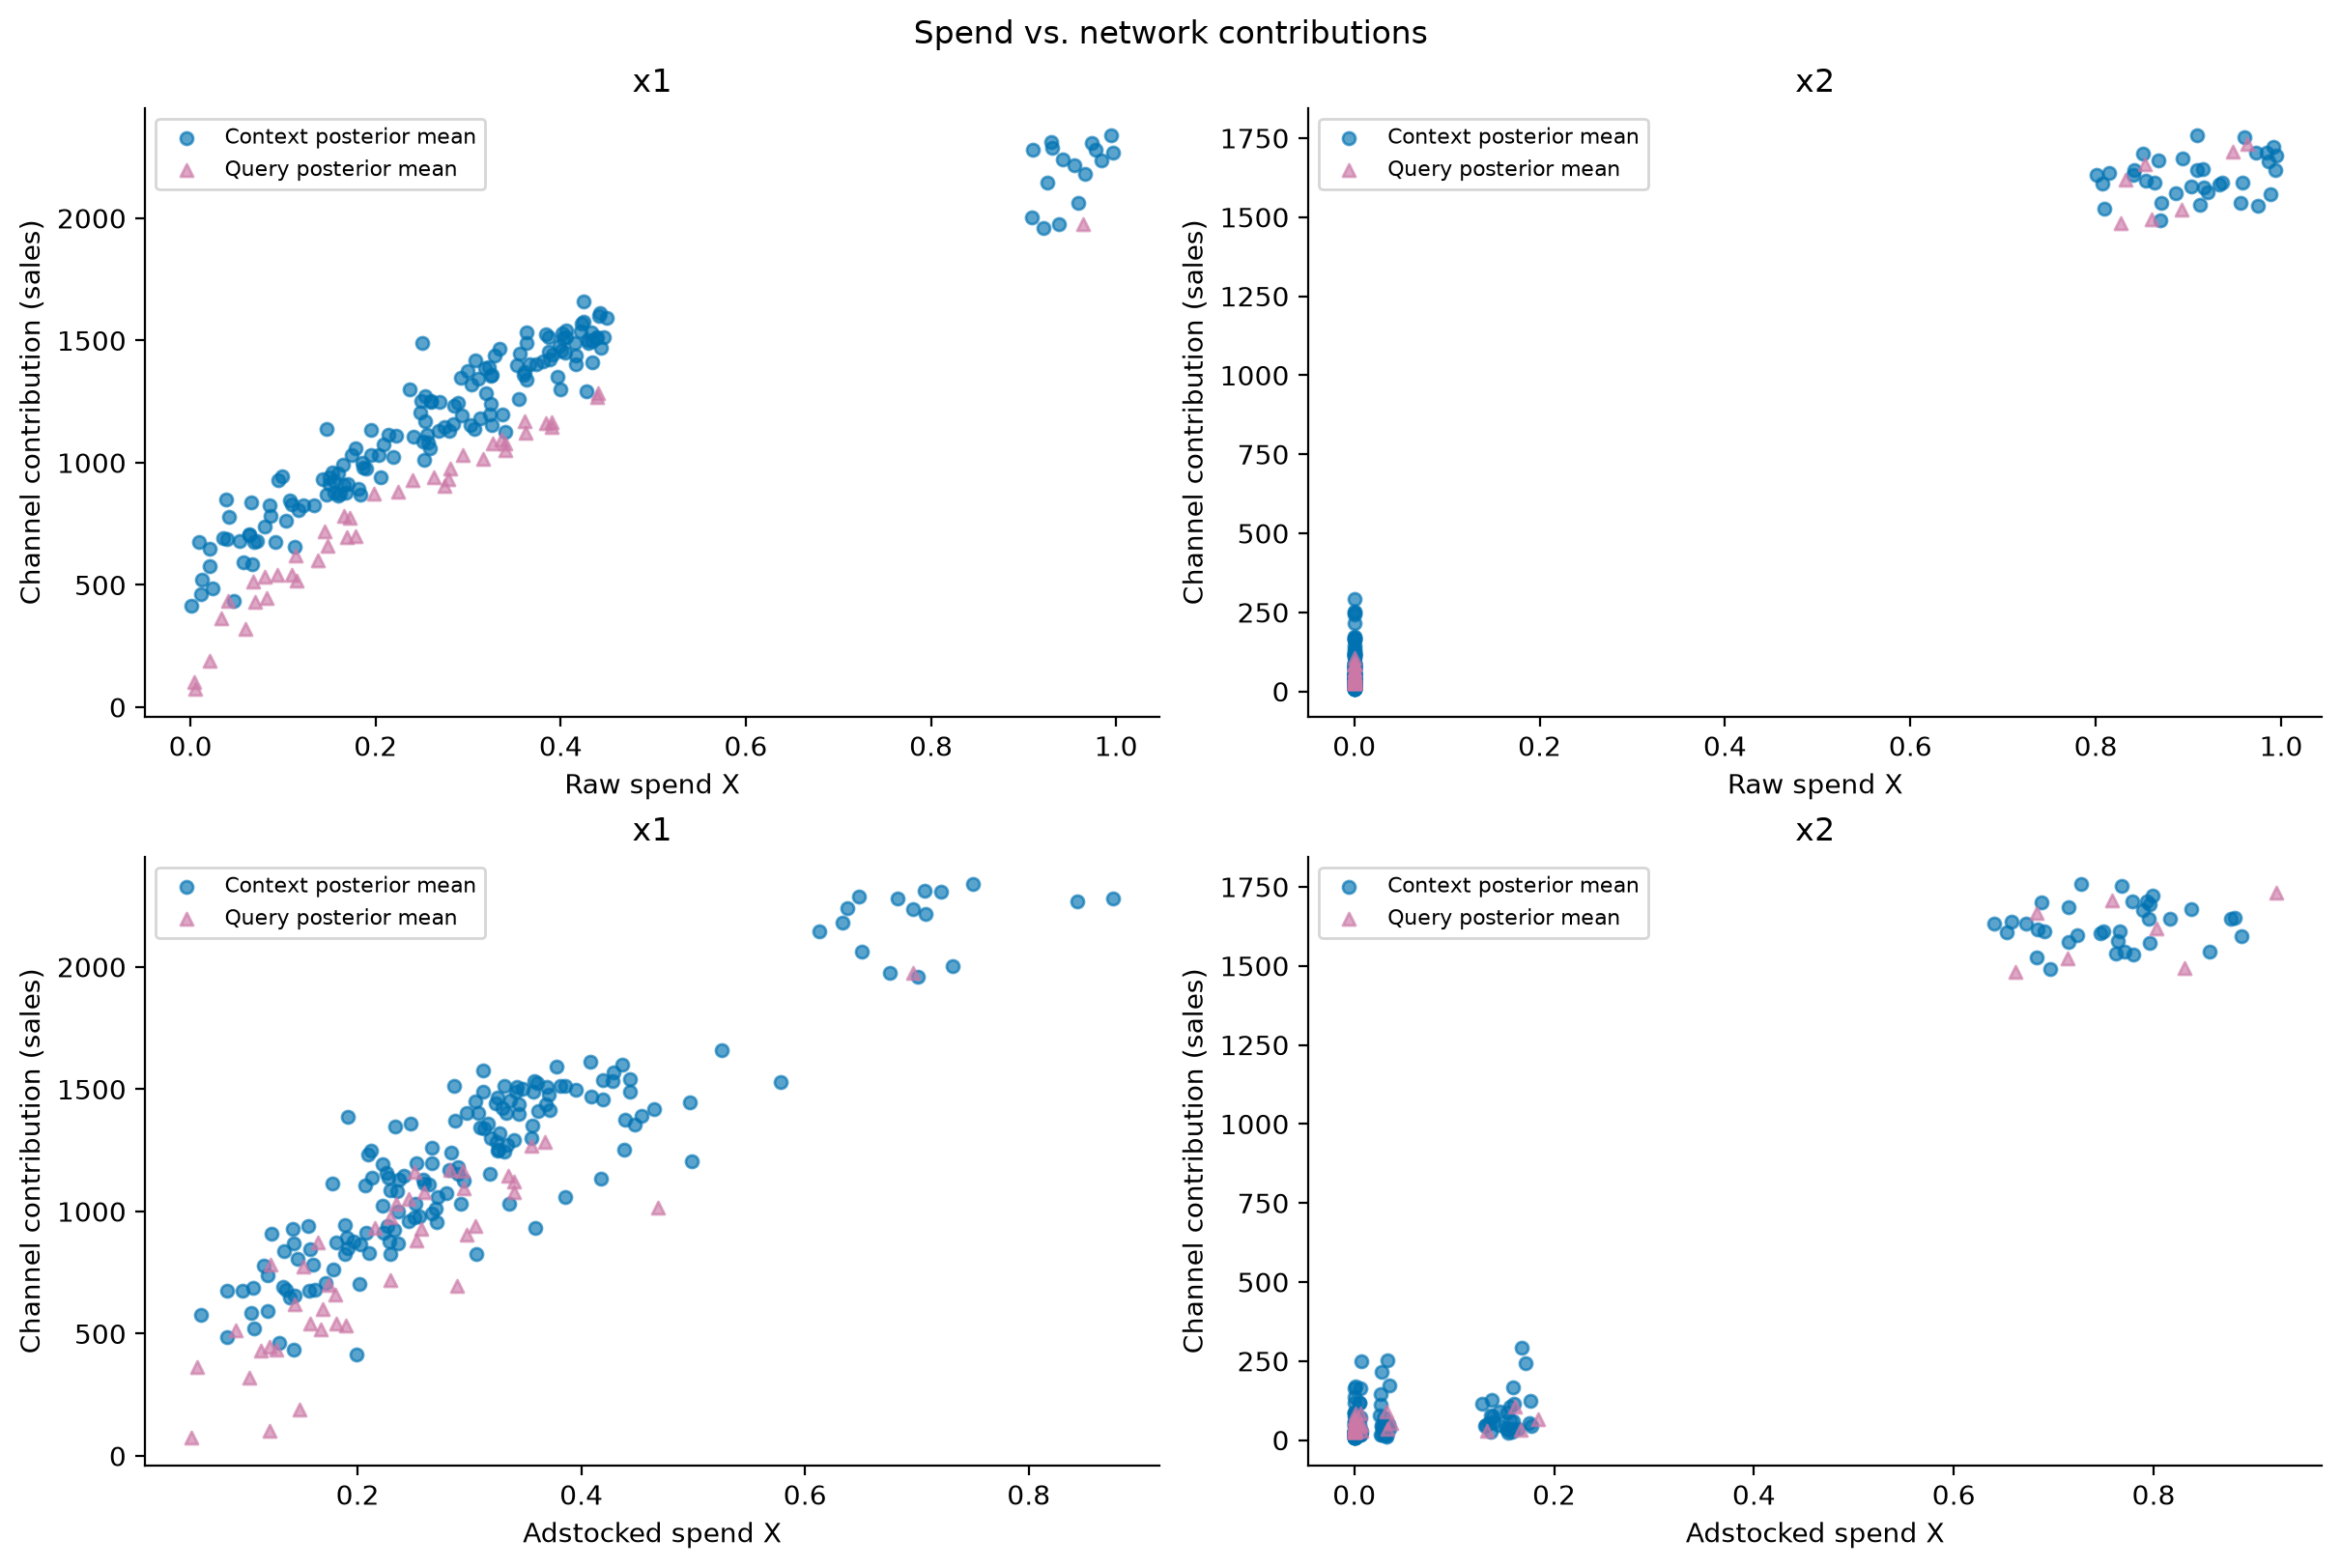

In [15]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharey="col", layout="constrained")
for column, (name, raw_x, adstocked_x) in enumerate(
    (("x1", x1, x1_adstock.eval()), ("x2", x2, x2_adstock.eval()))
):
    for row, (values, xlabel) in enumerate(
        ((raw_x, "Raw spend X"), (adstocked_x, "Adstocked spend X"))
    ):
        ax = axes[row, column]
        for result, marker, color in (
            (context, "o", COLORS["channel"]),
            (query, "^", COLORS["indirect"]),
        ):
            contribution = result.components[:, :, result.component_names.index(f"channel:{name}")]
            ax.scatter(
                values[result.time],
                contribution.mean(axis=0),
                s=22,
                alpha=0.65,
                marker=marker,
                color=color,
                label=f"{result.window.capitalize()} posterior mean",
            )
        ax.set(title=name, xlabel=xlabel, ylabel="Channel contribution (sales)")
        ax.spines[["top", "right"]].set_visible(False)
        ax.legend(fontsize=8)
fig.suptitle("Spend vs. network contributions");

## 9. Recap

- **No fit.** River-1 decomposed the series with one call per window, 1,000 posterior draws each,
  and no model fitted to this dataset. It saw the sales of the 166 context weeks only.
- **Media split.** In the context, the x1 share of media contribution is 0.77 against a true 0.79.
  Both channel totals are inside their 90% intervals but below the truth (x1 205,599 against
  261,603; x2 62,515 against 70,252).
- **Held-out sales.** In the 42 query weeks, whose sales it never saw, the model's weekly sales
  have a mean absolute error of 760 and 90% of the observed weeks fall inside its 90% interval. Its
  sales run below the observations in the second half of the query.
- **Query channels.** The x2 total is recovered (12,833 against 13,690). x1 is underestimated: its
  truth (51,407) is above the 90% interval (21,417 to 47,060), and the x1 share drops to 0.72.
- **Weekly shape.** The trajectories follow the timing of each channel. x2's bursts land in the
  right weeks, but the carryover after each burst is shorter than the truth and a small
  contribution remains between bursts, where the truth is zero. x1 follows the shape of its truth
  and sits below it in most weeks, most clearly in the query.
- **Events.** Both one-week events are placed in their week, with a lift centred below the truth
  (1,500 and 2,500); part of event_1 spills into the following weeks.
- **Posteriors.** Every effect is a distribution, not a point estimate: the histograms show its
  spread and where the truth falls in it. On this dataset the truth sits in the upper part of every
  channel and event posterior: River-1 leans towards under-attribution here, with wide intervals
  that usually, but not always, contain the truth.

In [16]:
workspace.cleanup()  # Delete the downloaded bundle.